In [1]:
%pylab inline

import gc
import glob
import fitsio
import anautil
import numpy as np
import matplotlib.cm as cm
import numpy.lib.recfunctions as rfn

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd /work/xiangchong.li/work/cosmicShear/photoz/

/work/xiangchong.li/work/cosmicShear/photoz


In [84]:
def main(pzname,iz=0):
    fieldname='XMM'
    datDir='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/'
    pzDir=os.path.join(datDir,'catalog_tracts','%s_tracts' %fieldname)
    pbins= pyfits.getdata(os.path.join(pzDir,'8522_pz_pdf_%s.fits' %pzname),ext=2)['BINS']
    inDir  =   os.path.join(datDir,'catalog_tracts','%s_tracts' %fieldname) 
    fnames=glob.glob(os.path.join(inDir,'*_pz_pdf_%s.fits' %(pzname)))
    pTest=[]
    for pfname in fnames[:10]:
        pata=pyfits.getdata(pfname)
        fname=pfname.split('pz_pdf')[0]+'pz.fits'
        data=pyfits.getdata(fname)
        if pzname != 'dempz':
            poz_best=data['%s_photoz_best' %pzname]
        else:
            poz_best=data['%s_photoz_best' %pzname[:-1]]
        del data,fname
        fname=pfname.split('pz_pdf')[0]+'no_m.fits'
        zmin=   (iz+1)*0.3
        zmax=   (iz+2)*0.3
        tmp_msk=(poz_best>zmin)&(poz_best<=zmax)
        pTest.append(pata[tmp_msk]['PDF'])
        del tmp_msk,pata
        gc.collect()
    pTest=np.vstack(pTest)
    out=np.log10(np.sum(pTest[:,pbins>2.],axis=1)/np.sum(pTest,axis=1))
    return pbins,pTest,out

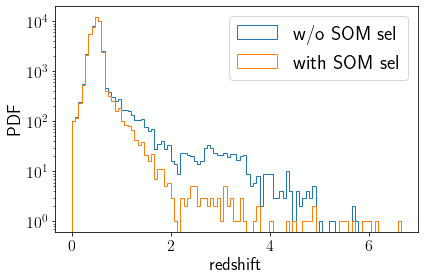

In [14]:
data=pyfits.getdata('mizuki_matched_spec_matched_SOM_markus.fits',ext=1)
data=data[data['BIN_SEL']]
msk=data['SOM_SEL']
plt.hist(data['redshift'],bins=100,label='w/o SOM sel',histtype='step');plt.hist(data['redshift'][msk],bins=100,label='with SOM sel',histtype='step')
plt.xlabel('redshift');plt.ylabel('PDF');plt.yscale('log');plt.legend();plt.tight_layout()

1.0
1.0


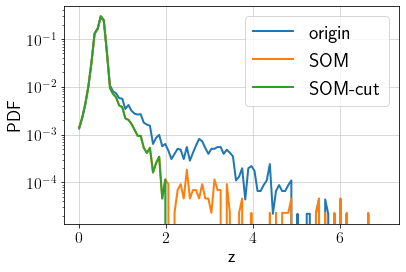

In [62]:
hdus=pyfits.open('hscy3_stack.fits')
zdata=hdus[1].data
zbounds=np.empty(len(zdata)+1)
zbounds[:-1]=zdata['Z_LOW']
zbounds[-1]=zdata['Z_HIGH'][-1]

bin1=np.histogram(data['redshift'],zbounds)[0]
sum1=np.sum(bin1)
bin1=bin1/sum1

bin11=np.histogram(data['redshift'][msk],zbounds)[0]
sum11=np.sum(bin11)
bin11=bin11/sum11
print(np.sum(bin11))

bin1c=bin11.copy()
bin1c[zdata['Z_MID']>2.]=0.
sum1c=np.sum(bin1c)
bin1c=bin1c/sum1c
print(np.sum(bin1c))

plt.plot(zdata['Z_MID'],bin1,label='origin')
plt.plot(zdata['Z_MID'],bin11,label='SOM')
plt.plot(zdata['Z_MID'],bin1c,label='SOM-cut')
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('PDF')
plt.grid()
plt.legend()

7868

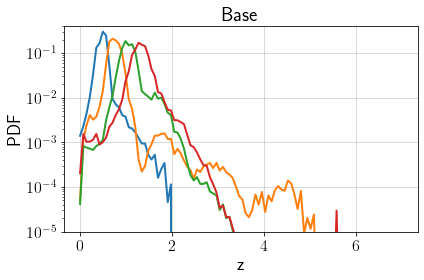

In [110]:
hdus=pyfits.open('hscy3_stack.fits')

zdata=hdus[1].data
zbounds=np.empty(len(zdata)+1)
zbounds[:-1]=zdata['Z_LOW']
zbounds[-1]=zdata['Z_HIGH'][-1]

bin1c=bin11.copy()
bin1c[zdata['Z_MID']>2.]=0.
sum1c=np.sum(bin1c)
bin1c=bin1c/sum1c
zdata['BIN1']=bin1c
zdata['BIN2']=zdata['BIN2']/np.sum(zdata['BIN2'])
zdata['BIN3']=zdata['BIN3']/np.sum(zdata['BIN3'])
zdata['BIN4']=zdata['BIN4']/np.sum(zdata['BIN4'])

hdus.writeto('hscy3_stack_bin1cut.fits',overwrite=True)
hdus=pyfits.open('hscy3_stack_bin1cut.fits')
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN1'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN2'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN3'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN4'])
plt.yscale('log')
plt.ylim(1e-5,4e-1)
plt.xlabel('z')
plt.ylabel('PDF')
plt.title('Base',fontsize=20)
plt.tight_layout()
plt.grid()
del hdus
gc.collect()

7868

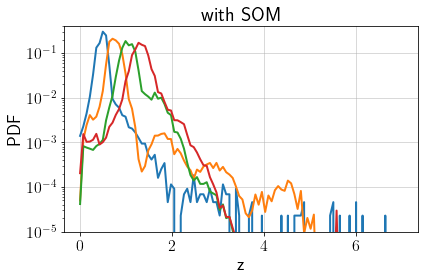

In [109]:
hdus=pyfits.open('hscy3_stack.fits')

zdata=hdus[1].data
zbounds=np.empty(len(zdata)+1)
zbounds[:-1]=zdata['Z_LOW']
zbounds[-1]=zdata['Z_HIGH'][-1]

bin11=np.histogram(data['redshift'][msk],zbounds)[0]
sum11=np.sum(bin11)
bin11=bin11/sum11

zdata['BIN1']=bin11
zdata['BIN2']=zdata['BIN2']/np.sum(zdata['BIN2'])
zdata['BIN3']=zdata['BIN3']/np.sum(zdata['BIN3'])
zdata['BIN4']=zdata['BIN4']/np.sum(zdata['BIN4'])
hdus.writeto('hscy3_stack_bin1som.fits',overwrite=True)
hdus=pyfits.open('hscy3_stack_bin1som.fits')
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN1'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN2'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN3'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN4'])
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('PDF')
plt.grid()
plt.ylim(1e-5,4e-1)
plt.title('with SOM',fontsize=20)
plt.tight_layout()
del hdus
gc.collect()

7868

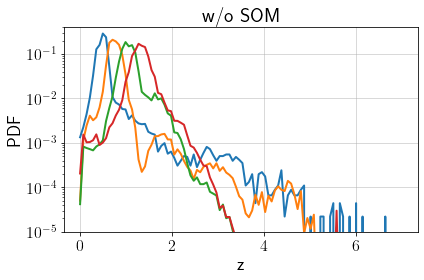

In [107]:
hdus=pyfits.open('hscy3_stack.fits')

zdata=hdus[1].data
zbounds=np.empty(len(zdata)+1)
zbounds[:-1]=zdata['Z_LOW']
zbounds[-1]=zdata['Z_HIGH'][-1]

bin10=np.histogram(data['redshift'],zbounds)[0]
sum10=np.sum(bin10)
bin10=bin10/sum10

zdata['BIN1']=bin10
zdata['BIN2']=zdata['BIN2']/np.sum(zdata['BIN2'])
zdata['BIN3']=zdata['BIN3']/np.sum(zdata['BIN3'])
zdata['BIN4']=zdata['BIN4']/np.sum(zdata['BIN4'])
hdus.writeto('hscy3_stack_bin1dp.fits',overwrite=True)
hdus=pyfits.open('hscy3_stack_bin1dp.fits')
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN1'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN2'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN3'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN4'])
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('PDF')
plt.grid()
plt.ylim(1e-5,4e-1)
plt.title('w/o SOM',fontsize=20)
plt.tight_layout()
del hdus
gc.collect()

/work/xiangchong.li/miniconda3/envs/cosmosis-mpich/lib/python3.7/site-packages/ipykernel_launcher.py:26: RuntimeWarning: divide by zero encountered in log10


155

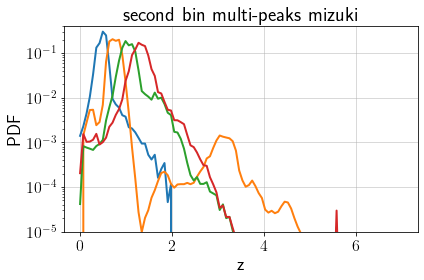

In [111]:
hdus=pyfits.open('hscy3_stack_bin1cut.fits')

zdata=hdus[1].data
zbounds=np.empty(len(zdata)+1)
zbounds[:-1]=zdata['Z_LOW']
zbounds[-1]=zdata['Z_HIGH'][-1]

pb2,pTest2,out2=main('mizuki',iz=1)
pstack2=np.average(pTest2,axis=0)

bin2dp=np.interp(zdata['Z_MID'],pb2, pstack2)
sum2=np.sum(bin2dp)
bin2dp=bin2dp/sum2

zdata['BIN1']=zdata['BIN1']/np.sum(zdata['BIN1'])
zdata['BIN2']=bin2dp
zdata['BIN3']=zdata['BIN3']/np.sum(zdata['BIN3'])
zdata['BIN4']=zdata['BIN4']/np.sum(zdata['BIN4'])
hdus.writeto('hscy3_stack_bin2dp.fits',overwrite=True)
hdus=pyfits.open('hscy3_stack_bin2dp.fits')
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN1'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN2'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN3'])
plt.plot(hdus[1].data['Z_MID'],hdus[1].data['BIN4'])
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('PDF')
plt.ylim(1e-5,4e-1)
plt.grid()
plt.title('second bin multi-peaks mizuki',fontsize=20)
plt.tight_layout()
del hdus
gc.collect()